# LaptopDSS — Notebook tái lập, kiểm định và phản biện

**Mục tiêu.** Notebook này tái lập chuỗi bằng chứng của dự án LaptopDSS: đọc snapshot dữ liệu, kiểm tra chất lượng, mô tả EDA, chạy DSS AHP–TOPSIS, đọc kết quả ML, đo hiệu năng và ghi rõ giới hạn. Đây là tài liệu kỹ thuật phục vụ bảo vệ, không phải công cụ tạo số liệu mới.

> Lưu ý liêm chính: Dữ liệu là snapshot 513 listing (505 CellphoneS, 8 FPT Shop pilot). Kết quả không phải khảo sát người dùng, không phải khuyến nghị tài chính, và không chứng minh giá hiện tại còn hiệu lực.

## 1. Câu hỏi nghiên cứu và thiết kế đánh giá

1. Với một nhu cầu và các ràng buộc cứng, laptop nào gần phương án lý tưởng nhất theo AHP–TOPSIS?
2. Dữ liệu có đủ độ phủ để từng tiêu chí được đưa vào điểm không?
3. Mô hình hồi quy giá có vượt baseline không, và sai số còn lớn đến đâu?
4. Kết quả có ổn định khi thay đổi ngân sách/trọng số không?

**Tách vai trò:** TOPSIS tạo điểm phù hợp đa tiêu chí; ML định giá tham chiếu bằng OOF. Giao diện có thể ghép hậu xử lý 85% TOPSIS + 15% điểm ML, nhưng không đưa ML vào ma trận TOPSIS.

In [1]:
from pathlib import Path
import json, sys, time, statistics
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')  # tái lập được cả khi chạy không có giao diện
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / 'data' / 'catalog' / 'laptops.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'catalog' / 'laptops.csv').exists(), 'Mở notebook từ thư mục notebooks hoặc project root.'
sys.path.insert(0, str(ROOT / 'src'))
from dss_ranking import PRESETS, compute_ahp_weights, evaluate, analyze_weight_sensitivity

DATA = ROOT / 'data' / 'catalog' / 'laptops.csv'
ARTIFACTS = ROOT / 'data' / 'artifacts'
REPORTS = ROOT / 'data' / 'reports'
print(f'Project root: {ROOT}')

Project root: D:\Dự Án DSS 1


## 2. Nạp dữ liệu và kiểm tra tính toàn vẹn

Các kiểm tra này trả lời trực tiếp câu hỏi phản biện: số mẫu có đúng không, nguồn có cân bằng không, có khóa định danh/URL trùng không, và tiêu chí nào có thể chấm điểm theo ngưỡng D14 (độ phủ ≥80%).

In [2]:
df = pd.read_csv(DATA, dtype=str, keep_default_na=False)
assert len(df) == 513, f'Expected 513 rows, found {len(df)}'
assert df['source_product_id'].is_unique
assert df['source_url'].is_unique
source_counts = df['source'].value_counts()
assert source_counts.get('cellphones', 0) == 505
assert source_counts.get('FPT Shop', 0) == 8
weights = pd.to_numeric(df['weight_kg'], errors='coerce')
assert weights.dropna().between(0.4, 5.0).all(), 'weight_kg outside plausible laptop range'
display(source_counts.rename_axis('source').reset_index(name='listings'))
print('Integrity checks: PASS — 513 rows, unique product IDs/URLs, retailer split verified.')

Integrity checks: PASS — 513 rows, unique product IDs/URLs, retailer split verified.


,source,listings
0,cellphones,505
1,FPT Shop,8


In [3]:
coverage_fields = ['sale_price_vnd','ram_gb','storage_total_gb','weight_kg','cpu_benchmark_multi_core','cpu_benchmark_single_core','refresh_rate_hz','brightness_nits','ram_slots']
coverage = pd.DataFrame({
    'field': coverage_fields,
    'present': [(df[c] != '').sum() for c in coverage_fields],
})
coverage['coverage_%'] = (coverage['present'] / len(df) * 100).round(1)
coverage['D14_status'] = np.where(coverage['coverage_%'] >= 80, 'eligible for scoring', 'display/filter only')
display(coverage)
# GPU Time Spy is meaningful only for discrete GPUs, so report both denominators.
dgpu = df[df['gpu_type'].eq('discrete')]
print(f"GPU Time Spy: {(df['gpu_benchmark_time_spy'] != '').sum()}/{len(df)} overall; {(dgpu['gpu_benchmark_time_spy'] != '').sum()}/{len(dgpu)} among dGPU.")

GPU Time Spy: 163/513 overall; 163/164 among dGPU.


,field,present,coverage_%,D14_status
0,sale_price_vnd,513,100.0,eligible for scoring
1,ram_gb,513,100.0,eligible for scoring
2,storage_total_gb,513,100.0,eligible for scoring
3,weight_kg,510,99.4,eligible for scoring
4,cpu_benchmark_multi_core,439,85.6,eligible for scoring
5,cpu_benchmark_single_core,439,85.6,eligible for scoring
6,refresh_rate_hz,430,83.8,eligible for scoring
7,brightness_nits,406,79.1,display/filter only
8,ram_slots,402,78.4,display/filter only


## 3. EDA tối thiểu nhưng tái lập

EDA mô tả snapshot, không suy luận dân số. Giá được hiển thị theo triệu VNĐ; biểu đồ giúp nhận diện lệch phải và lý do mô hình ML dự báo trên log(price).

notebooks\LaptopDSS_End_to_End_Audit.ipynb:cell-4:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,price_vnd
count,5.130000e+02
mean,3.726261e+07
std,2.247349e+07
min,8.790000e+06
25%,2.399000e+07
50%,2.959000e+07
75%,4.199000e+07
max,1.999900e+08


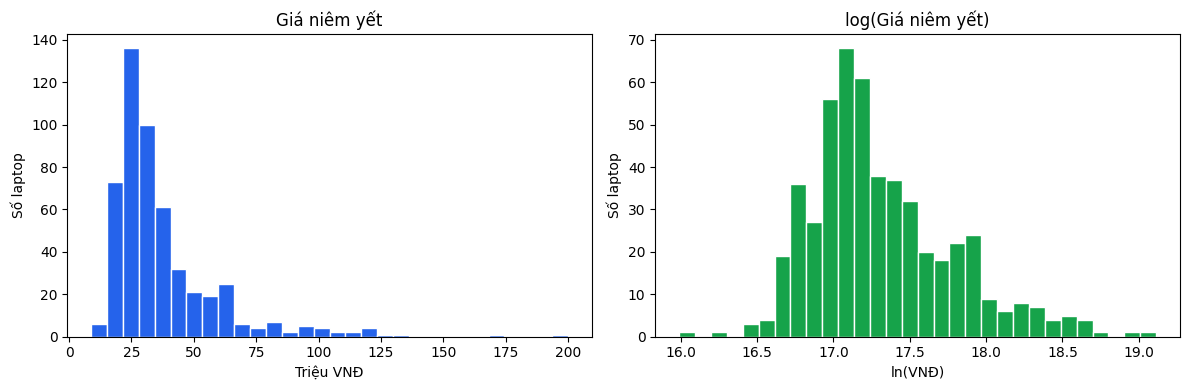

In [4]:
price = pd.to_numeric(df['sale_price_vnd'], errors='coerce')
summary = price.describe(percentiles=[.25, .5, .75]).to_frame('price_vnd')
display(summary)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(price / 1e6, bins=30, color='#2563eb', edgecolor='white')
ax[0].set(title='Giá niêm yết', xlabel='Triệu VNĐ', ylabel='Số laptop')
ax[1].hist(np.log(price), bins=30, color='#16a34a', edgecolor='white')
ax[1].set(title='log(Giá niêm yết)', xlabel='ln(VNĐ)', ylabel='Số laptop')
plt.tight_layout()
plt.show()

## 4. DSS: AHP, ràng buộc cứng và TOPSIS

Mỗi profile dùng ma trận so sánh cặp. Chỉ số nhất quán CR < 0.10 là điều kiện cần để ma trận được chấp nhận. Trước TOPSIS, chương trình lọc ràng buộc ngân sách/OS/RAM/SSD; Gaming luôn bắt buộc Windows, dGPU và 144Hz. Các giá trị thiếu của tiêu chí còn lại không bị gán 0: nếu coverage <80% tiêu chí bị loại, nếu ≥80% thì bản ghi thiếu bị loại rõ lý do.

In [5]:
ahp_rows = []
for key in ['student_budget', 'slim_mobility', 'technical_coding', 'gaming']:
    weights, lambda_max, cr = compute_ahp_weights(PRESETS[key]['matrix'])
    assert cr < 0.10
    ahp_rows.append({'preset': key, 'lambda_max': round(lambda_max, 4), 'CR': round(cr, 4), 'weights': ', '.join(f'{w:.1%}' for w in weights)})
display(pd.DataFrame(ahp_rows))

,preset,lambda_max,CR,weights
0,student_budget,5.0331,0.0074,"40.2%, 24.5%, 13.7%, 13.7%, 7.9%"
1,slim_mobility,5.0735,0.0164,"42.5%, 25.3%, 15.0%, 9.9%, 7.2%"
2,technical_coding,5.0680,0.0152,"43.0%, 26.0%, 9.2%, 15.8%, 6.1%"
3,gaming,5.0680,0.0152,"41.7%, 26.3%, 16.0%, 9.7%, 6.2%"


In [6]:
records = df.to_dict('records')
case = evaluate(records, preset_key='technical_coding', max_budget_vnd=25_000_000, min_ram_gb=16, min_storage_gb=512)
assert case['status'] in {'success', 'single_candidate'}
top = pd.DataFrame(case['rankings'][:5])
display(top[['rank','product_name_raw','sale_price_vnd','ram_gb','storage_total_gb','cpu_benchmark_multi_core','topsis_score']])
print('Active criteria:', case['active_criteria'])
print('Excluded:', len(case['excluded']), '| Dropped criteria:', case['dropped_criteria'])

Active criteria: [('cpu_benchmark_multi_core', 'benefit', 0.4301060407055067), ('ram_gb', 'fit', 0.2595335693030299), ('sale_price_vnd', 'cost', 0.09186266458857813), ('storage_total_gb', 'fit', 0.15789096908823247), ('weight_kg', 'cost', 0.060606756314652926)]
Excluded: 411 | Dropped criteria: []


,rank,product_name_raw,sale_price_vnd,ram_gb,storage_total_gb,cpu_benchmark_multi_core,topsis_score
0,1,Laptop Lenovo ThinkPad E14 Gen 7 21T90022VA,23990000,16,1024,12800.0,0.8484
1,2,Laptop ASUS VivoBook 14 M1407GA-LY270W,23690000,16,512,13200.0,0.8449
2,3,Laptop Lenovo ThinkBook 14 G8 IRL 21SG007TVN,22990000,16,512,12800.0,0.8390
3,4,Laptop Lenovo ThinkBook 16 G8 IRL 21SH0099VN,22990000,16,512,12800.0,0.8339
4,5,Laptop Lenovo ThinkPad E14 Gen 7 21T90021VA,23990000,16,512,12800.0,0.8332


## 5. Kiểm thử phản biện DSS

Đây không phải đánh giá “người dùng hài lòng”; đây là các assert bảo vệ các hứa hẹn thuật toán. Tình huống Gaming dưới đây là regression test cho lỗi trước đây: máy 60Hz hoặc thiếu Hz không được lọt vào danh sách Gaming ngay cả khi caller quên truyền filter UI.

In [7]:
gaming = evaluate(records, preset_key='gaming', max_budget_vnd=50_000_000)
assert all(float(x['refresh_rate_hz']) >= 144 for x in gaming['rankings'])
assert all(x['os_name'] == 'Windows' and x['gpu_type'] == 'discrete' for x in gaming['rankings'])
print(f"Gaming constraint test: PASS — {len(gaming['rankings'])} ranked laptops are Windows + dGPU + >=144Hz.")

sensitivity = analyze_weight_sensitivity(records, preset_key='technical_coding', max_budget_vnd=25_000_000)
print('OAT Top-1 stability (%):', sensitivity['stability_rate_percent'])
print('Interpretation: a high value means the current Top-1 survives tested one-at-a-time weight perturbations; it does not validate user preference weights.')

Gaming constraint test: PASS — 98 ranked laptops are Windows + dGPU + >=144Hz.
OAT Top-1 stability (%): 90.0
Interpretation: a high value means the current Top-1 survives tested one-at-a-time weight perturbations; it does not validate user preference weights.


## 6. ML định giá: benchmark tái lập và artifact triển khai

Cell sau huấn luyện lại **5 mô hình bắt buộc của đề bài** (Linear Regression, KNN, Decision Tree, Random Forest, ANN) bằng Nested GroupKFold 5 outer folds / 3 inner folds. Kết quả chỉ hiển thị trong notebook, **không ghi đè artifact demo**. Sau đó notebook đọc artifact triển khai đã khóa để đối chiếu. So sánh dùng MAE/MAPE/R² cùng baseline; không chỉ nêu R².

**Lưu ý trung thực về ANN:** với mẫu snapshot nhỏ và không đồng nhất này, một số inner fold của bộ tối ưu L-BFGS có thể chạm giới hạn vòng lặp (`ConvergenceWarning`). Chỉ số ANN vẫn được ghi rõ để đối chiếu, nhưng ANN **không phải mô hình triển khai**; mô hình triển khai là Gradient Boosting được chọn theo Nested GroupKFold. Warning không bị ẩn và không được diễn giải là ANN đã hội tụ hoàn toàn.

In [8]:
from ml_price_prediction import assemble_feature_matrix, evaluate_models_nested_groupkfold, load_dataset

CORE_MODELS = ['Linear Regression', 'K-Nearest Neighbors Regressor', 'Decision Tree Regressor', 'Random Forest Regressor', 'MLP Regressor (ANN)']
ml_records, brands = load_dataset()
X_ml, y_ml, y_log_ml, groups_ml, _ = assemble_feature_matrix(ml_records, brands)
fresh_cv, _, _ = evaluate_models_nested_groupkfold(X_ml, y_ml, y_log_ml, groups_ml, model_names=CORE_MODELS)
fresh_table = pd.DataFrame(fresh_cv).T.rename_axis('model').reset_index()
display(fresh_table[['model', 'r2_mean', 'mae_mean', 'rmse_mean', 'mape_mean']].round({'r2_mean': 4, 'mae_mean': 0, 'rmse_mean': 0, 'mape_mean': 2}))
print('ANN note: a ConvergenceWarning, if emitted above, means an inner L-BFGS fit hit its iteration limit. ANN is comparison-only and is not deployed.')

metrics = json.loads((ARTIFACTS / 'price_model_metrics.json').read_text(encoding='utf-8'))
print('Model deployed:', metrics['best_model'])
print('Samples:', metrics['dataset_size'], '| Features:', metrics['features_count'], '| sigma(log-price):', metrics['sigma_pred_log'])
model_table = pd.DataFrame(metrics['models_cv']).T.rename_axis('model').reset_index()
display(model_table[['model', 'r2_mean', 'mae_mean', 'rmse_mean', 'mape_mean']].round({'r2_mean': 4, 'mae_mean': 0, 'rmse_mean': 0, 'mape_mean': 2}))
print('Defense wording: ML is a reference valuation. In optional UI mode it contributes 15% after TOPSIS; a ~4.6M VND MAE means individual predictions remain uncertain.')


NESTED GROUPKFOLD EVALUATION (5-FOLD OUTER, 3-FOLD INNER GRIDSEARCHCV)
[Linear Regression               ] R2: +0.8500 ± 0.0287 | MAE:   5,378,828 ±   505,338 VND | MAPE: 14.34%
[K-Nearest Neighbors Regressor   ] R2: +0.7977 ± 0.0320 | MAE:   5,822,125 ±   353,013 VND | MAPE: 14.56%
[Decision Tree Regressor         ] R2: +0.7861 ± 0.0581 | MAE:   6,176,099 ±   881,255 VND | MAPE: 15.82%
[Random Forest Regressor         ] R2: +0.9023 ± 0.0199 | MAE:   4,599,702 ±   604,240 VND | MAPE: 12.35%
C:\Users\DieuKhongNgu\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:606: ConvergenceWarning: lbfgs failed to converge after 600 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=600).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_r

,model,r2_mean,mae_mean,rmse_mean,mape_mean
0,Linear Regression,0.84999,5378827.736781,8592556.438637,14.343752
1,K-Nearest Neighbors Regressor,0.797727,5822125.256462,9979641.820732,14.555016
2,Decision Tree Regressor,0.786147,6176098.97481,10294868.109344,15.818967
3,Random Forest Regressor,0.902306,4599701.530524,6982101.633599,12.350394
4,MLP Regressor (ANN),0.840578,5696267.319073,8905803.260782,14.900964


,model,r2_mean,mae_mean,rmse_mean,mape_mean
0,Baseline (Mean Log-Price),-0.041739,14174184.116744,22768807.547009,36.391469
1,Linear Regression,0.84999,5378827.736781,8592556.438637,14.343752
2,Ridge Regression,0.856785,5324051.775205,8405408.733773,14.250222
3,K-Nearest Neighbors Regressor,0.797727,5822125.256462,9979641.820732,14.555016
4,Decision Tree Regressor,0.786147,6176098.97481,10294868.109344,15.818967
5,Random Forest Regressor,0.902306,4599701.530524,6982101.633599,12.350394
6,Gradient Boosting,0.903433,4544509.704018,6935911.401339,12.235344
7,LightGBM Regressor,0.852057,4877960.890443,8498843.08747,12.482339
8,XGBoost Regressor,0.902306,4357566.529583,6934194.136752,11.925199
9,MLP Regressor (ANN),0.840578,5696267.319073,8905803.260782,14.900964


### 6.1. Chạy model đã train trên một cấu hình mới

Cell này dùng artifact Gradient Boosting đã khóa để định giá một cấu hình nhập tay, không lấy lại giá của một dòng catalog. Đây là cùng luồng với form **Định giá cấu hình mới** trên giao diện và endpoint `/api/predict_price`.

In [9]:
from api import PredictPriceRequest, build_prediction_vector, get_model_pipeline

new_config = PredictPriceRequest(
    cpu_benchmark_multi=12000, cpu_benchmark_single=2500,
    gpu_benchmark_time_spy=6000, is_discrete_gpu=True, gpu_vram_gb=6,
    ram_gb=16, storage_total_gb=512, refresh_rate_hz=144,
    brightness_nits=300, battery_capacity_wh=60, weight_kg=2.2,
    brand='Asus', observed_price_vnd=20_000_000,
)
pipeline = get_model_pipeline(ARTIFACTS / 'price_model.joblib')
raw_vector = build_prediction_vector(new_config, pipeline['feature_names'])
scaled_vector = pipeline['scaler'].transform(raw_vector)
imputed_vector = pipeline['imputer'].transform(scaled_vector)
pred_log = float(pipeline['model'].predict(imputed_vector)[0])
predicted_vnd = float(np.exp(pred_log))
sigma = float(pipeline['sigma_pred'])
lower_vnd, upper_vnd = np.exp(pred_log - 1.96 * sigma), np.exp(pred_log + 1.96 * sigma)
gap_pct = (predicted_vnd - new_config.observed_price_vnd) / predicted_vnd * 100
display(pd.DataFrame([{
    'model': pipeline['model_name'], 'gia_dang_ban_vnd': new_config.observed_price_vnd,
    'gia_du_bao_vnd': round(predicted_vnd, -4), 'can_du_bao_95_vnd': round(lower_vnd, -4),
    'can_tren_du_bao_95_vnd': round(upper_vnd, -4), 'chenh_lech_voi_tham_chieu_pct': round(gap_pct, 2),
}]))
print('Đây là dự báo tham chiếu từ model, không phải cam kết giá thị trường hoặc khuyến nghị mua.')

Đây là dự báo tham chiếu từ model, không phải cam kết giá thị trường hoặc khuyến nghị mua.


,model,gia_dang_ban_vnd,gia_du_bao_vnd,can_du_bao_95_vnd,can_tren_du_bao_95_vnd,chenh_lech_voi_tham_chieu_pct
0,Gradient Boosting,20000000.0,34940000.0,25450000.0,47970000.0,42.76


## 7. Đo hiệu năng tái lập

Đo 100 lần in-memory trên cùng catalog, không tính thời gian khởi động Python, đọc file, mạng hay trình duyệt. Đây là benchmark engine đơn luồng tại máy chạy notebook; không được diễn giải như tải production/concurrent users.

In [10]:
timings_ms = []
for _ in range(100):
    t0 = time.perf_counter()
    evaluate(records, preset_key='technical_coding', max_budget_vnd=35_000_000)
    timings_ms.append((time.perf_counter() - t0) * 1_000)
bench = {'runs': len(timings_ms), 'mean_ms': statistics.mean(timings_ms), 'median_ms': statistics.median(timings_ms), 'p95_ms': np.percentile(timings_ms, 95), 'max_ms': max(timings_ms)}
display(pd.DataFrame([bench]).round(2))

,runs,mean_ms,median_ms,p95_ms,max_ms
0,100,4.8,3.89,5.28,78.52


## 8. Kết luận, giới hạn và câu trả lời bảo vệ

**Đã chứng minh:** engine tái lập trên snapshot, các ràng buộc cứng và độ phủ được kiểm tra, CR đạt ngưỡng, ML vượt baseline nội bộ, và latency in-memory thấp cho quy mô 513 bản ghi. Snapshot có trường `collected_at` cho mọi listing (17/10/2026).

**Chưa được chứng minh:** độ hài lòng người dùng, độ chính xác giá theo thời gian, tổng quát hóa tới retailer thứ ba, hiệu năng đa người dùng, hay ưu thế thống kê chắc chắn giữa Gradient Boosting và XGBoost. Mặc dù có `collected_at`, mỗi listing chỉ có một quan sát giá nên không thể làm temporal validation. FPT có 8 mẫu trong catalog; sau khi loại 1 cấu hình trùng train/test, holdout còn 7 mẫu nên không được gọi là external validation mạnh.

**Nếu bị hỏi KNN/Decision Tree/ANN:** pipeline có KNN Regressor, Decision Tree Regressor và MLP/ANN thật để so sánh, ngoài KNNImputer dùng trong tiền xử lý. Chúng không được triển khai vì Gradient Boosting dẫn đầu theo $R^2$ của Nested GroupKFold trong artifact hiện hành.